In [1]:
# Assignment 5: Predictive Maintenance from Sensor Logs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(
    r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-5-Predictive-Maintenance-from-Sensor-Logs\ai4i2020.csv"
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of rows: 10000
Number of columns: 14

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      1000

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [5]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
failure_counts = df["Machine failure"].value_counts()

print("Machine failure distribution:")
print(failure_counts)

print("\nFailure rate: %.2f percent" % (
    df["Machine failure"].mean() * 100
))

Machine failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39 percent


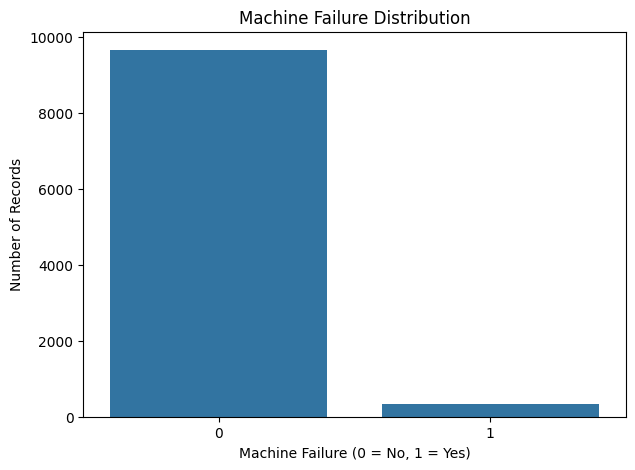

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

Recorded failure modes:
HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


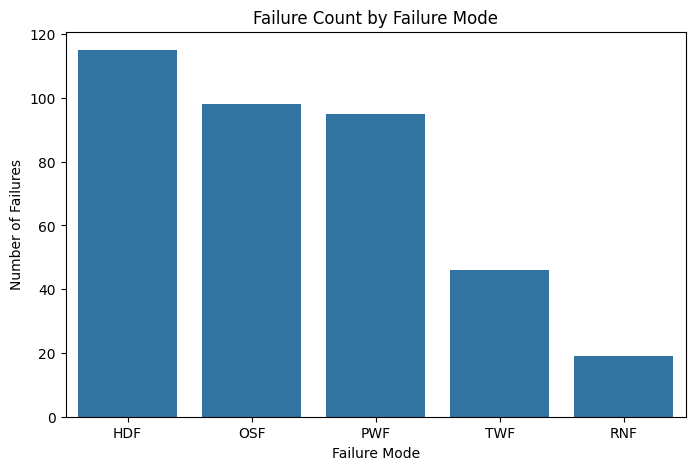

In [8]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

mode_counts = df[failure_modes].sum().sort_values(ascending=False)

print("Recorded failure modes:")
print(mode_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=mode_counts.index,
    y=mode_counts.values
)

plt.title("Failure Count by Failure Mode")
plt.xlabel("Failure Mode")
plt.ylabel("Number of Failures")
plt.show()

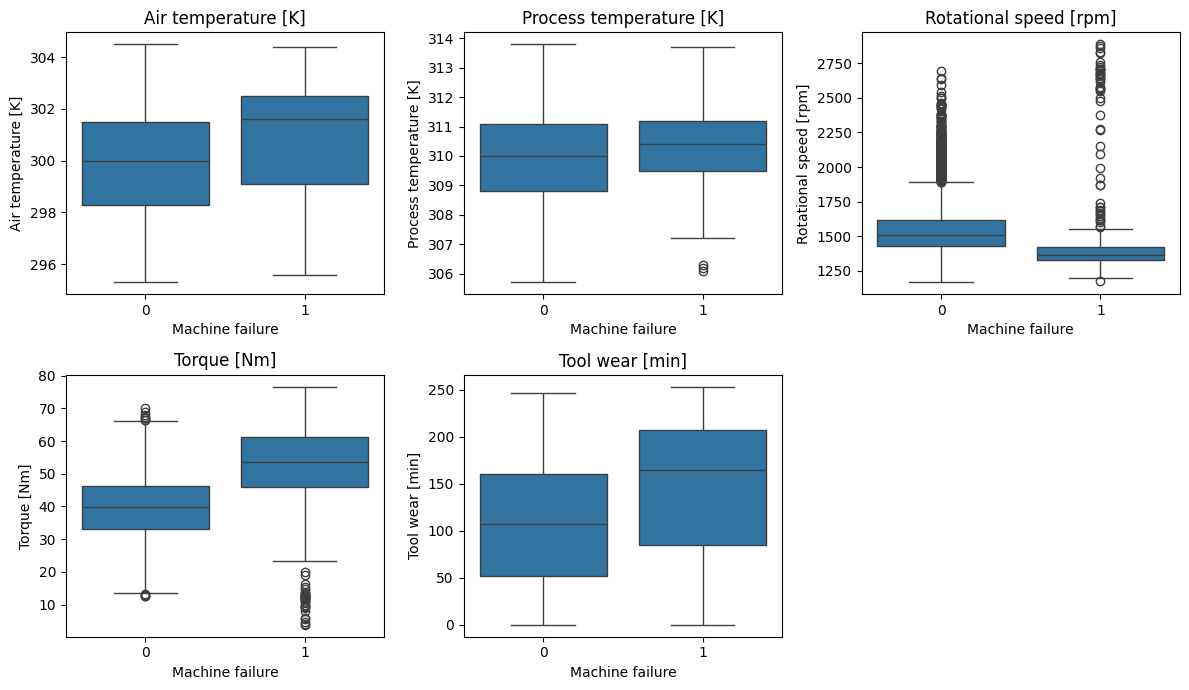

In [9]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

plt.figure(figsize=(12, 7))

for i, column in enumerate(sensor_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column
    )
    plt.title(column)

plt.tight_layout()
plt.show()

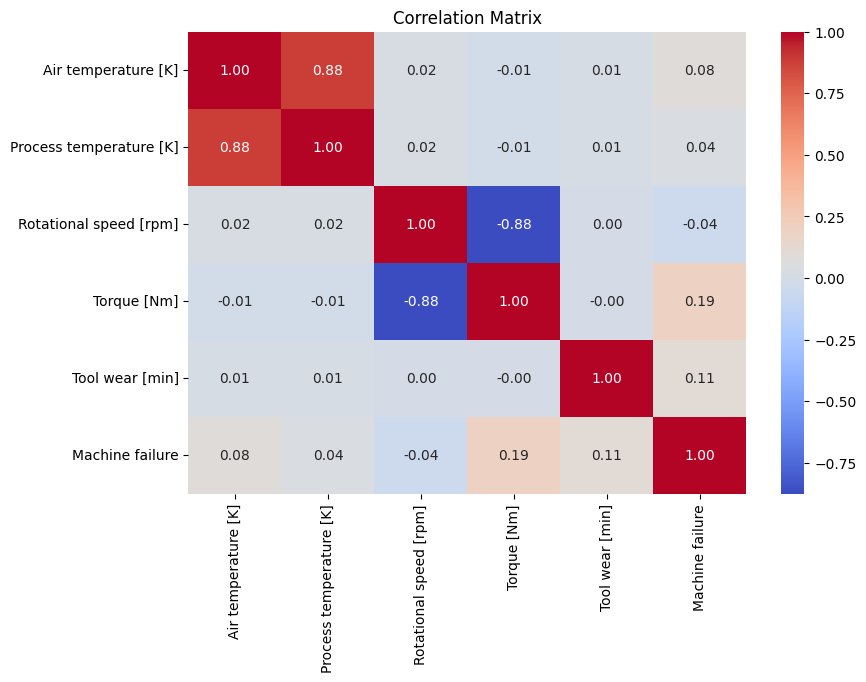

In [10]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df[sensor_columns + ["Machine failure"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

Product quality distribution:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


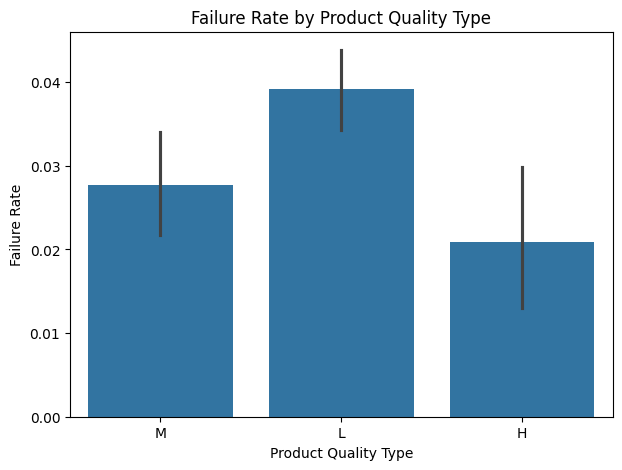

In [11]:
print("Product quality distribution:")
print(df["Type"].value_counts())

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Type",
    y="Machine failure"
)

plt.title("Failure Rate by Product Quality Type")
plt.xlabel("Product Quality Type")
plt.ylabel("Failure Rate")
plt.show()

In [12]:
# UDI and Product ID are identifiers, and the individual failure mode
# flags together define the target, so all of them are removed
df_model = df.drop(
    columns=["UDI", "Product ID"] + failure_modes
)

df_model = pd.get_dummies(
    df_model,
    columns=["Type"],
    drop_first=True,
    dtype=int
)

print("Columns used for modelling:")
print(df_model.columns.tolist())

Columns used for modelling:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'Type_L', 'Type_M']


In [13]:
X = df_model.drop("Machine failure", axis=1)
y = df_model["Machine failure"]

print("Number of features:", X.shape[1])
print("Failures in dataset:", y.sum())

Number of features: 7
Failures in dataset: 339


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Failures in training set:", y_train.sum())
print("Failures in testing set:", y_test.sum())

Training samples: 8000
Testing samples: 2000
Failures in training set: 271
Failures in testing set: 68


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled.")

Features scaled.


In [16]:
results = []


def evaluate_model(name, model):
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy, 3),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3)
    })

    print(name)
    print("Accuracy  :", round(accuracy, 3))
    print("Precision :", round(precision, 3))
    print("Recall    :", round(recall, 3))
    print("F1 Score  :", round(f1, 3))

    return predictions

In [17]:
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_predictions = evaluate_model(
    "Logistic Regression",
    logistic_model
)

Logistic Regression
Accuracy  : 0.968
Precision : 0.636
Recall    : 0.103
F1 Score  : 0.177


In [18]:
# Failures are only about three percent of the data, so class weights
# are used to stop the model from ignoring the minority class
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_predictions = evaluate_model(
    "Logistic Regression (balanced)",
    balanced_model
)

Logistic Regression (balanced)
Accuracy  : 0.825
Precision : 0.142
Recall    : 0.824
F1 Score  : 0.242


In [19]:
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

forest_predictions = evaluate_model(
    "Random Forest",
    forest_model
)

Random Forest
Accuracy  : 0.982
Precision : 0.878
Recall    : 0.529
F1 Score  : 0.661


In [20]:
results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1
2,Random Forest,0.982,0.878,0.529,0.661
1,Logistic Regression (balanced),0.825,0.142,0.824,0.242
0,Logistic Regression,0.968,0.636,0.103,0.177


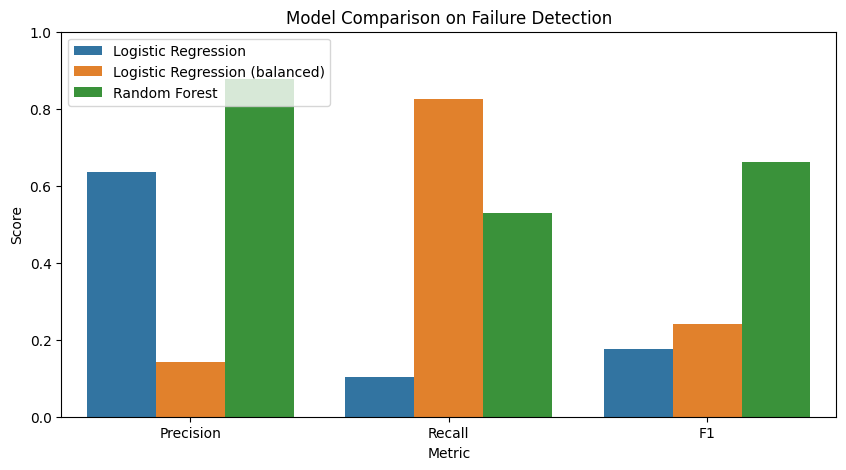

In [21]:
comparison = results_df.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Comparison on Failure Detection")
plt.ylim(0, 1)
plt.legend(loc="upper left")
plt.show()

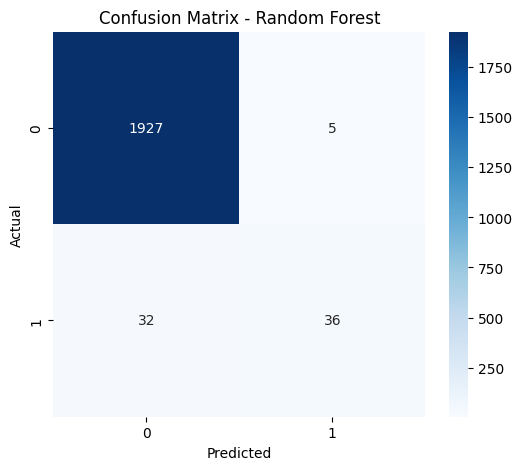

True negatives : 1927
False positives: 5
False negatives: 32
True positives : 36


In [22]:
matrix = confusion_matrix(y_test, forest_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("True negatives :", matrix[0][0])
print("False positives:", matrix[0][1])
print("False negatives:", matrix[1][0])
print("True positives :", matrix[1][1])

In [23]:
print("Classification Report - Random Forest")
print(classification_report(
    y_test,
    forest_predictions,
    target_names=["No Failure", "Failure"]
))

Classification Report - Random Forest
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.88      0.53      0.66        68

    accuracy                           0.98      2000
   macro avg       0.93      0.76      0.83      2000
weighted avg       0.98      0.98      0.98      2000



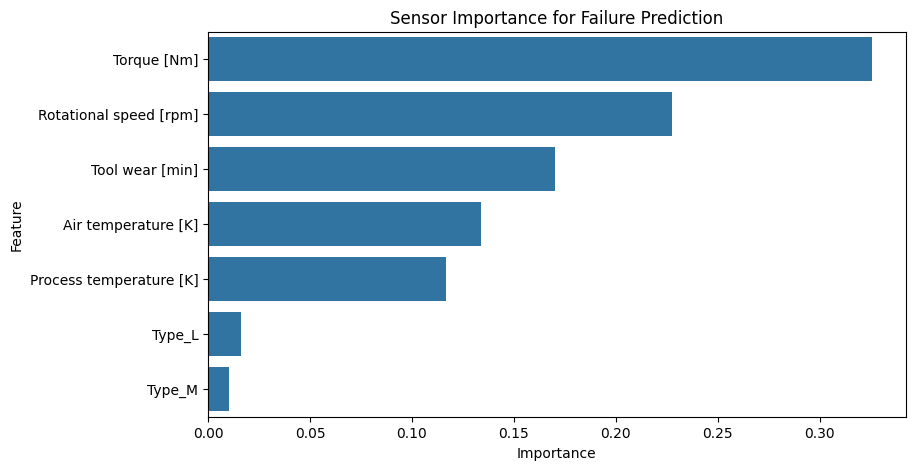

,Feature,Importance
3,Torque [Nm],0.325802
2,Rotational speed [rpm],0.227445
4,Tool wear [min],0.170059
0,Air temperature [K],0.133696
1,Process temperature [K],0.116563
5,Type_L,0.016373
6,Type_M,0.010063


In [24]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": forest_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Sensor Importance for Failure Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

importance

In [25]:
sample_readings = X_test.iloc[[0, 1, 2, 3, 4]]

sample_scaled = scaler.transform(sample_readings)

sample_predictions = forest_model.predict(sample_scaled)

sample_output = sample_readings.copy()
sample_output["Actual"] = y_test.iloc[[0, 1, 2, 3, 4]].values
sample_output["Predicted"] = sample_predictions

sample_output

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M,Actual,Predicted
2997,300.5,309.8,1345,62.7,153,1,0,0,0
4871,303.7,312.4,1513,40.1,135,1,0,0,0
3858,302.5,311.4,1559,37.6,209,1,0,0,0
951,295.6,306.3,1509,35.8,60,0,0,0,0
6463,300.5,310.0,1358,60.4,102,0,0,0,0


In [26]:
best_model = results_df.sort_values(by="F1", ascending=False).iloc[0]

print("PREDICTIVE MAINTENANCE - SUMMARY")
print("----------------------------------")
print("Records analysed :", df.shape[0])
print("Failures recorded:", int(df["Machine failure"].sum()))
print("Failure rate     : %.2f percent" % (df["Machine failure"].mean() * 100))
print("Best model       :", best_model["Model"])
print("Accuracy         :", best_model["Accuracy"])
print("Precision        :", best_model["Precision"])
print("Recall           :", best_model["Recall"])
print("F1 Score         :", best_model["F1"])

PREDICTIVE MAINTENANCE - SUMMARY
----------------------------------
Records analysed : 10000
Failures recorded: 339
Failure rate     : 3.39 percent
Best model       : Random Forest
Accuracy         : 0.982
Precision        : 0.878
Recall           : 0.529
F1 Score         : 0.661
